# Williams-Otto PWL-tanh MILP Benchmark

**Goal.** Turn a smooth `tanh` surrogate of the Williams-Otto reactor into an
exact **mixed-integer linear program** by replacing every `tanh` with a manual
piecewise-linear (PWL) block, and check that the resulting MILP recommends the
same operating point as the exact tanh NLP — but as a *global* optimum a linear
solver (HiGHS / MOSEK) can certify.

**Why the constraint outputs get special treatment.** The surrogate predicts six
mass fractions, two of which — `XA` and `XG` — are the process operating limits
(`XA <= 0.12`, `XG <= 0.08`). Once the network is embedded, the optimizer
enforces those limits on the surrogate's *predicted* `XA`/`XG`, so the curve it
treats as the feasibility boundary is wherever the **surrogate** says
`XA = 0.12` (resp. `XG = 0.08`), not where the true process does. If the
surrogate is even slightly off near the limit, the MILP can pick a point that is
feasible for the surrogate yet infeasible for the real reactor. We therefore
**penalise the `XA`/`XG` outputs more heavily during training**, keep an
unweighted baseline for comparison, and **plot the learned constraint boundary
against the exact one** to see how far apart they sit.

**Roadmap.**

1. PWL approximation quality of `tanh` for the 3/5/7-piece breakpoint sets.
2. Two `tanh` surrogates trained on Williams-Otto data — an unweighted baseline
   and a constraint-weighted network — and how much the extra penalty tightens
   the learned `XA`/`XG` boundary.
3. The exact smooth tanh embedding (OMLT NLP, Ipopt) as the reference optimum.
4. The manual **big-M PWL-tanh MILP** (HiGHS / MOSEK), sweeping the PWL pieces.
5. The Phase-2 objective formulations — **MAE (MILP)**, **MSE-QP (MIQP)** and
   **MSE-SOCP (MISOCP)** — on an inverse-design problem solved with MOSEK.
6. Constrained vs unconstrained operating points, with the learned and exact
   feasibility boundaries drawn on the profit landscape.

The companion SOS2 formulation (`tanh_pwl_sos2`) builds the same network as SOS2
constraints; it needs a solver with native SOS2 support (Gurobi, CPLEX, CBC,
SCIP), so this notebook benchmarks the big-M variant that HiGHS and MOSEK solve.


In [1]:
from __future__ import annotations

import os
import sys
import time
from pathlib import Path


def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "src" / "pwlnet").exists() and (candidate / "pyproject.toml").exists():
            return candidate
    raise RuntimeError("Could not find the PWLNet project root.")


# Fallback for kernels without an editable `pip install -e .` of pwlnet.
ROOT = find_project_root(Path.cwd().resolve())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import LogLocator, LogFormatterSciNotation
import numpy as np
import pandas as pd
import pyomo.environ as pyo

from pwlnet import PWLNet, metrics_table, train_val_test_split
from pwlnet.formulations.pyomo_pwl import (
    build_tanh_pwl_data,
    build_tanh_pwl_bigm_model,
    evaluate_tanh_pwl_network,
)
from pwlnet.objectives import attach_data_loss
from pwlnet.processes.williams_otto import (
    EXACT_OPTIMUM,
    INPUT_NAMES,
    OUTPUT_NAMES,
    WilliamsOttoParameters,
    generate_dataset,
    solve_steady_state,
    solve_surrogate_optimization_model,
)
from pwlnet.solvers.solver_config import (
    find_ipopt,
    get_conic_solver,
    get_milp_solver,
    mosek_license_available,
)
from pwlnet.utils.exceptions import SolverNotAvailableError

plt.style.use("seaborn-v0_8-whitegrid")
params = WilliamsOttoParameters()

HAS_IPOPT = find_ipopt() is not None
HAS_MOSEK = mosek_license_available()
print(f"Ipopt available: {HAS_IPOPT}")
print(f"MOSEK available: {HAS_MOSEK}")


Ipopt available: True
MOSEK available: True


## PWL approximation quality

The standard breakpoint sets from the SOSX paper span `[-4, 4]`; outside that
range the formulations extend the function with flat saturation segments, which
matches `tanh` to within `1 - tanh(4) < 1e-3`.


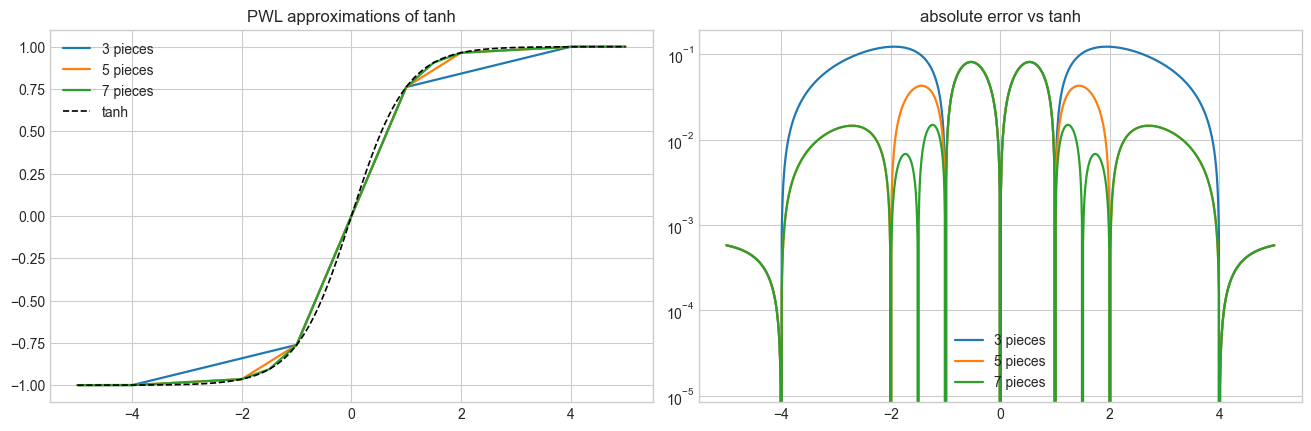

,pieces,breakpoints,max_abs_error_on_domain
0,3,4,0.123450
1,5,6,0.081741
2,7,8,0.081741


In [2]:
z = np.linspace(-5.0, 5.0, 1001)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
rows = []
for pieces in (3, 5, 7):
    pwl = build_tanh_pwl_data(pieces)
    axes[0].plot(z, pwl.evaluate(z), linewidth=1.6, label=f"{pieces} pieces")
    axes[1].plot(z, np.abs(pwl.evaluate(z) - np.tanh(z)), linewidth=1.6, label=f"{pieces} pieces")
    rows.append({
        "pieces": pieces,
        "breakpoints": pwl.n_breakpoints,
        "max_abs_error_on_domain": pwl.max_abs_error(np.tanh),
    })
axes[0].plot(z, np.tanh(z), "k--", linewidth=1.2, label="tanh")
axes[0].set_title("PWL approximations of tanh")
axes[0].legend()
axes[1].set_title("absolute error vs tanh")
axes[1].set_yscale("log")
axes[1].legend()
plt.show()

pd.DataFrame(rows)


## Train a tanh surrogate on Williams-Otto data

Same supervised task as notebook 02: `(FB, TR)` to six reactor mass fractions.


In [3]:
# Shared experiment configuration (identical across notebooks 01-03):
# 150 Latin-hypercube samples split 60/20/20 into train/validation/test
# with one fixed seed, so all three notebooks train and evaluate on the
# exact same partitions.
RANDOM_SEED = 7
DATA_CONFIG = dict(n_samples=150, method="lhs", random_state=RANDOM_SEED)
VAL_SIZE, TEST_SIZE = 0.2, 0.2

data = generate_dataset(**DATA_CONFIG, as_frame=True)
split = train_val_test_split(data, val_size=VAL_SIZE, test_size=TEST_SIZE, random_state=RANDOM_SEED)
train_df, val_df, test_df = split.train, split.validation, split.test


def split_xy(frame):
    return frame[INPUT_NAMES].to_numpy(dtype=float), frame[OUTPUT_NAMES].to_numpy(dtype=float)


X_train, y_train = split_xy(train_df)
X_val, y_val = split_xy(val_df)
X_test, y_test = split_xy(test_df)

# Dense regular 21x21 grid for landscape contour plots (pivot-based
# contouring needs a full mesh; the LHS samples are scattered).
plot_grid = generate_dataset(n_samples=441, method="grid", random_state=RANDOM_SEED, as_frame=True)

print(f"data: {len(data)} samples -> train {len(train_df)} / val {len(val_df)} / test {len(test_df)}")

# XA and XG are the operating-constraint outputs (XA <= 0.12, XG <= 0.08).
# Once the surrogate is embedded, the optimizer enforces those limits on the
# *predicted* XA/XG, so error there moves the feasibility boundary the MILP
# trusts. We therefore train the surrogate with a heavier loss weight on
# XA/XG, and keep an unweighted baseline to measure what the penalty buys.
CONSTRAINT_OUTPUTS = ["XA", "XG"]
CONSTRAINT_WEIGHT = 10.0
output_loss_weights = [
    CONSTRAINT_WEIGHT if name in CONSTRAINT_OUTPUTS else 1.0 for name in OUTPUT_NAMES
]

train_kwargs = dict(
    hidden_layers=[10],
    activation="tanh",
    loss="mse",
    epochs=1000,
    batch_size=16,
    validation_data=(X_val, y_val),
    early_stopping_patience=25,
    random_seed=RANDOM_SEED,
    verbose=0,
)

# Unweighted baseline: equal weight on all six outputs.
net_baseline = PWLNet.train(X_train, y_train, **train_kwargs)

# Constraint-weighted surrogate: XA/XG penalised CONSTRAINT_WEIGHT x more.
# This is the network embedded and optimized everywhere downstream.
net = PWLNet.train(X_train, y_train, output_loss_weights=output_loss_weights, **train_kwargs)

# Train/validation/test prediction quality of the constraint-weighted surrogate.
smooth_metrics = metrics_table(
    {
        "train": (y_train, net.predict(X_train)),
        "validation": (y_val, net.predict(X_val)),
        "test": (y_test, net.predict(X_test)),
    }
)
print(smooth_metrics.to_string(index=False))

# PWL approximation error of the constraint-weighted network, on the test split.
smooth_pred = net.predict(X_test)
rows = []
for pieces in (3, 5, 7):
    pwl_pred = evaluate_tanh_pwl_network(net.network, X_test, breakpoints=pieces)
    rows.append({
        "pieces": pieces,
        "PWL surrogate test MAE": float(np.mean(np.abs(pwl_pred - y_test))),
        "max |PWL - smooth| on test": float(np.max(np.abs(pwl_pred - smooth_pred))),
    })
pd.DataFrame(rows)

data: 150 samples -> train 90 / val 30 / test 30


     split      MAE      MSE     RMSE       R2  n_samples
     train 0.001129 0.000004 0.001903 0.997428         90
validation 0.001180 0.000004 0.002043 0.996770         30
      test 0.001327 0.000005 0.002279 0.996096         30


,pieces,PWL surrogate test MAE,max |PWL - smooth| on test
0,3,0.003404,0.012228
1,5,0.002579,0.009998
2,7,0.002419,0.009742


## Williams-Otto landscape and surrogate fit

The same diagnostics used in notebooks 01 and 02: the exact benchmark landscape, the training history with train/test parity, and the surrogate-implied profit surface of the trained tanh network.

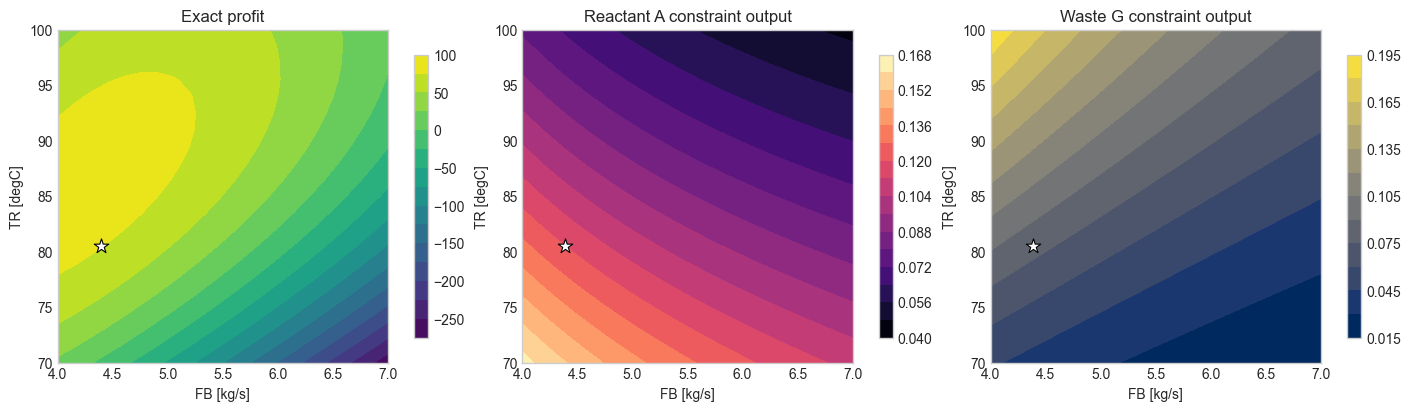

In [4]:
def grid_values(frame, column):
    table = frame.pivot(index="TR", columns="FB", values=column).sort_index()
    return table.columns.to_numpy(dtype=float), table.index.to_numpy(dtype=float), table.to_numpy(dtype=float)


fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, column, title, cmap in zip(
    axes,
    ["profit", "XA", "XG"],
    ["Exact profit", "Reactant A constraint output", "Waste G constraint output"],
    ["viridis", "magma", "cividis"],
):
    fb_grid, tr_grid, z = grid_values(plot_grid, column)
    contour = ax.contourf(fb_grid, tr_grid, z, levels=14, cmap=cmap)
    ax.scatter([EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]], marker="*", s=120, color="white", edgecolor="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")
    fig.colorbar(contour, ax=ax, shrink=0.85)

plt.show()


### Training history and mass-fraction parity

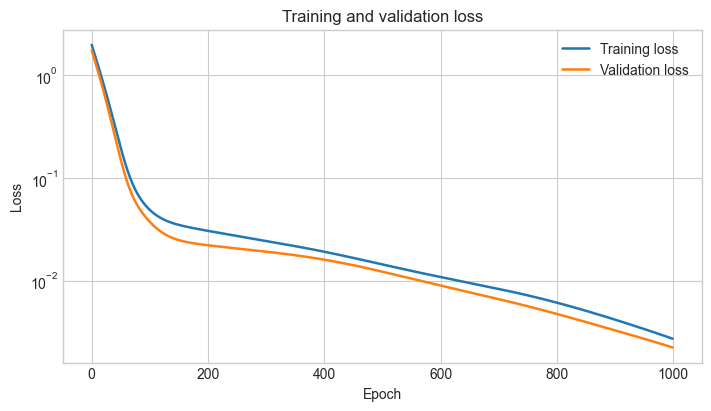

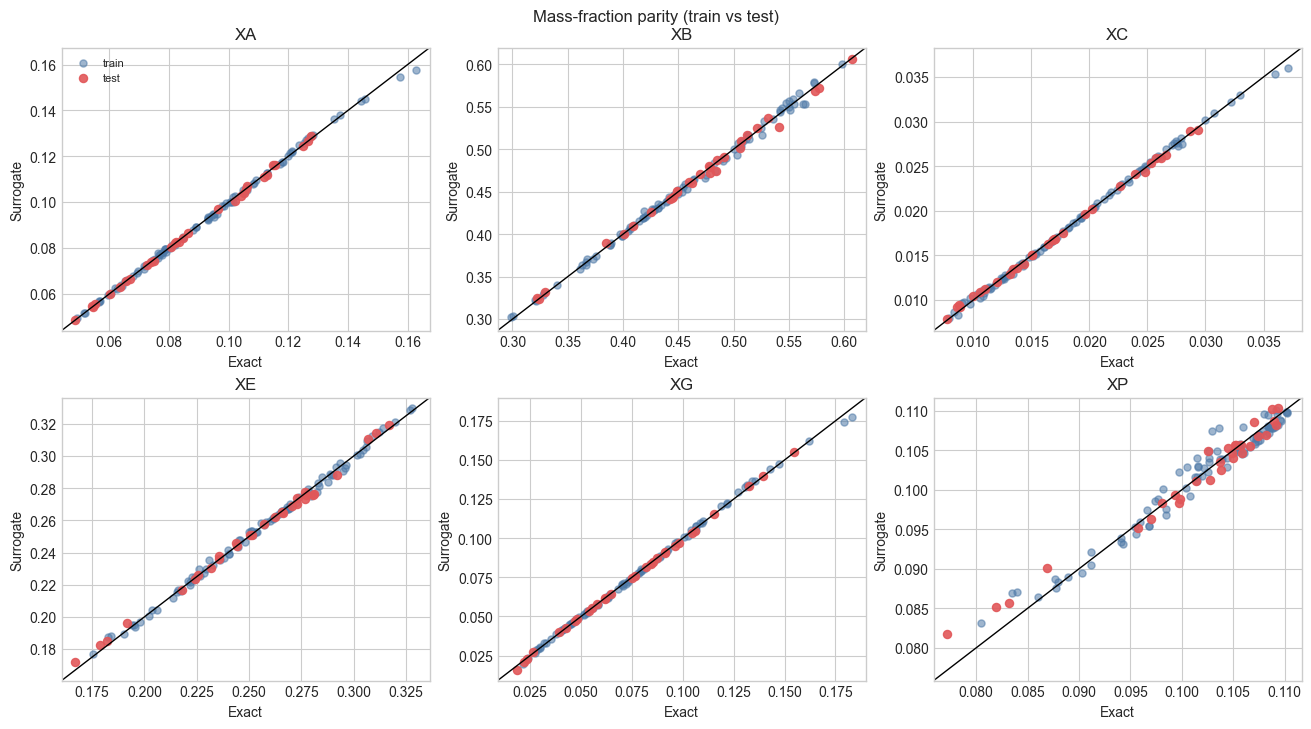

In [5]:
history = net.trainer.history_ or {}

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(history.get("loss", []), linewidth=1.8, label="Training loss")
if "val_loss" in history:
    ax.plot(history["val_loss"], linewidth=1.8, label="Validation loss")
ax.set_title("Training and validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_yscale("log")
ax.legend()
plt.show()

pred_train = net.predict(X_train)
pred_test = net.predict(X_test)

fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for ax, name, j in zip(axes.ravel(), OUTPUT_NAMES, range(len(OUTPUT_NAMES))):
    ax.scatter(y_train[:, j], pred_train[:, j], s=26, alpha=0.55, color="#4e79a7", label="train")
    ax.scatter(y_test[:, j], pred_test[:, j], s=34, alpha=0.9, color="#e15759", label="test")
    cat = np.concatenate([y_train[:, j], y_test[:, j], pred_train[:, j], pred_test[:, j]])
    lo, hi = float(cat.min()), float(cat.max())
    pad = 0.04 * max(hi - lo, 1e-6)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="black", linewidth=1.0)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_title(name)
    ax.set_xlabel("Exact")
    ax.set_ylabel("Surrogate")
axes.ravel()[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Mass-fraction parity (train vs test)", y=1.02)
plt.show()


### Surrogate-implied profit landscape

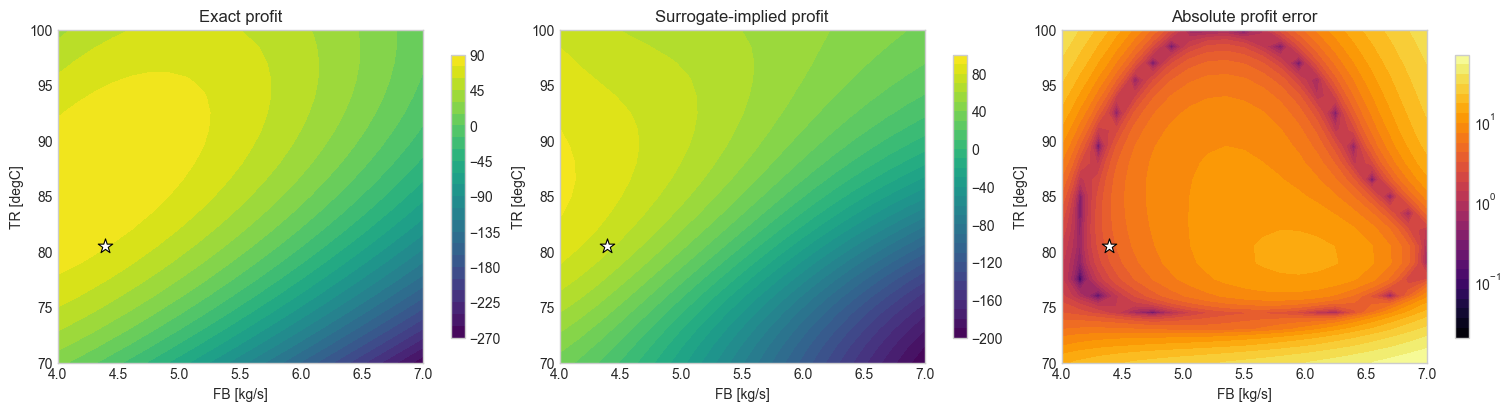

In [6]:
plot_data = plot_grid.copy()
pred_grid = net.predict(plot_data[INPUT_NAMES].to_numpy(dtype=float))
for i, name in enumerate(OUTPUT_NAMES):
    plot_data[f"{name}_pred"] = pred_grid[:, i]

flow = params.fa + plot_data["FB"].to_numpy(dtype=float)
plot_data["profit_pred"] = (
    (params.price_p * plot_data["XP_pred"].to_numpy(dtype=float)
     + params.price_e * plot_data["XE_pred"].to_numpy(dtype=float))
    * flow
    - params.cost_a * params.fa
    - params.cost_b * plot_data["FB"].to_numpy(dtype=float)
)
plot_data["profit_abs_error"] = np.abs(plot_data["profit_pred"] - plot_data["profit"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

for ax, column, title, cmap in zip(
    axes,
    ["profit", "profit_pred", "profit_abs_error"],
    ["Exact profit", "Surrogate-implied profit", "Absolute profit error"],
    ["viridis", "viridis", "inferno"],
):
    fb_grid, tr_grid, z = grid_values(plot_data, column)

    if column == "profit_abs_error":
        positive = z[np.isfinite(z) & (z > 0)]

        eps = positive.min() / 1 if positive.size else 1e-12
        z_plot = np.where(z > 0, z, eps)

        vmin = z_plot.min()
        vmax = z_plot.max()

        levels = np.logspace(np.log10(vmin), np.log10(vmax), 30)

        contour = ax.contourf(
            fb_grid,
            tr_grid,
            z_plot,
            levels=levels,
            cmap=cmap,
            norm=LogNorm(vmin=vmin, vmax=vmax)
        )

        cbar = fig.colorbar(contour, ax=ax, shrink=0.85)
        cbar.locator = LogLocator(base=10, numticks=20)
        cbar.formatter = LogFormatterSciNotation(base=10)
        cbar.update_ticks()

    else:
        contour = ax.contourf(
            fb_grid,
            tr_grid,
            z,
            levels=30,
            cmap=cmap
        )

        fig.colorbar(contour, ax=ax, shrink=0.85)

    ax.scatter(
        [EXACT_OPTIMUM["FB"]],
        [EXACT_OPTIMUM["TR"]],
        marker="*",
        s=120,
        color="white",
        edgecolor="black",
        linewidth=0.8
    )

    ax.set_title(title)
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")

plt.show()

### Learned vs exact constraint boundaries

This is the figure that matters for feasibility. The embedded optimizer never
sees the true `XA`/`XG`; it sees the surrogate's predictions, so it treats the
**learned** contour `XA_pred = 0.12` (resp. `XG_pred = 0.08`) as the feasibility
limit. Below, the filled field is the *exact* `XA`/`XG`, the white line is the
true limit, and the two coloured curves are the learned limit for the unweighted
baseline and the constraint-weighted network. Where a learned curve sits *inside*
the true-feasible region the surrogate is conservative (safe); where it sits
*outside*, the MILP can pick a point the real reactor rejects.

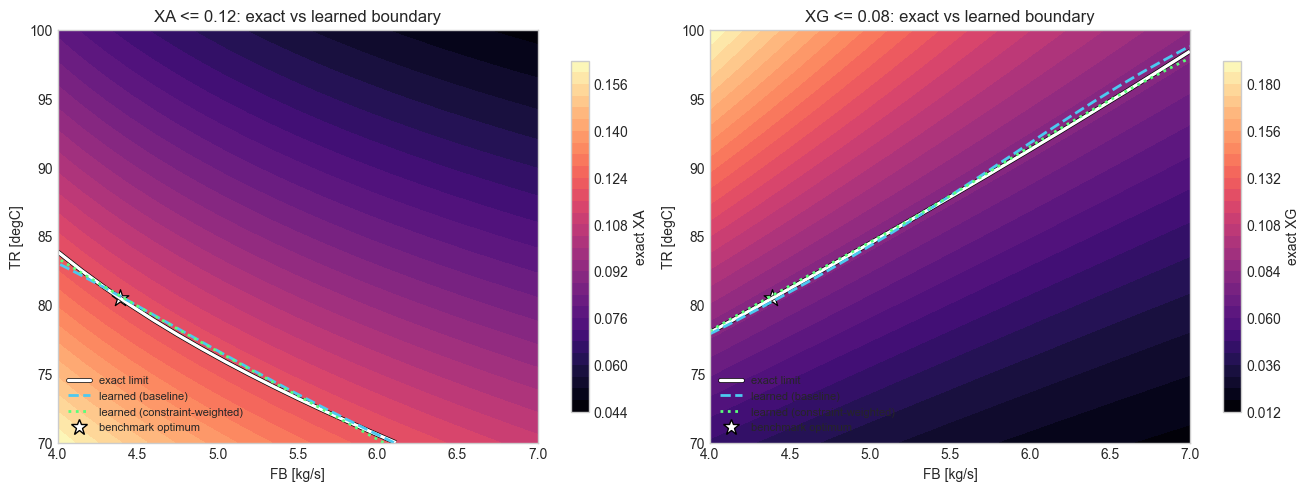

In [7]:
# Learned vs exact constraint boundaries. The MILP enforces XA <= 0.12 and
# XG <= 0.08 on the SURROGATE's predicted outputs, so the curve it treats as
# the feasibility limit is where the surrogate predicts the limit -- not where
# the true process does. We overlay that learned boundary for BOTH networks on
# the exact field, so the gap to the white exact line is the constraint error,
# and the shift from the baseline (dashed) to the weighted (dotted) curve is
# what the extra penalty buys.
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

pred_grid_baseline = net_baseline.predict(plot_grid[INPUT_NAMES].to_numpy(dtype=float))
for i, name in enumerate(OUTPUT_NAMES):
    plot_data[f"{name}_pred_baseline"] = pred_grid_baseline[:, i]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
for ax, name, limit in zip(axes, CONSTRAINT_OUTPUTS, [params.xa_max, params.xg_max]):
    fb_grid, tr_grid, exact = grid_values(plot_data, name)
    _, _, learned = grid_values(plot_data, f"{name}_pred")
    _, _, learned_base = grid_values(plot_data, f"{name}_pred_baseline")
    contour = ax.contourf(fb_grid, tr_grid, exact, levels=30, cmap="magma")
    fig.colorbar(contour, ax=ax, shrink=0.85, label=f"exact {name}")
    exact_line = ax.contour(fb_grid, tr_grid, exact, levels=[limit], colors="white", linewidths=2.4)
    exact_line.set_path_effects([pe.Stroke(linewidth=3.4, foreground="black"), pe.Normal()])
    ax.contour(fb_grid, tr_grid, learned_base, levels=[limit], colors="#4cc9f0", linewidths=2.0, linestyles="dashed")
    ax.contour(fb_grid, tr_grid, learned, levels=[limit], colors="#59ff7a", linewidths=2.0, linestyles="dotted")
    ax.scatter([EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]], marker="*", s=160, color="white", edgecolor="black", linewidth=0.9)
    ax.set_title(f"{name} <= {limit:g}: exact vs learned boundary")
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")
    handles = [
        Line2D([0], [0], color="white", lw=2.4, path_effects=[pe.Stroke(linewidth=3.4, foreground="black"), pe.Normal()], label="exact limit"),
        Line2D([0], [0], color="#4cc9f0", lw=2.0, linestyle="dashed", label="learned (baseline)"),
        Line2D([0], [0], color="#59ff7a", lw=2.0, linestyle="dotted", label="learned (constraint-weighted)"),
        Line2D([0], [0], marker="*", color="white", markeredgecolor="black", markersize=12, linestyle="None", label="benchmark optimum"),
    ]
    ax.legend(handles=handles, loc="lower left", fontsize=8, framealpha=0.92)
plt.show()

## Reference: exact smooth tanh embedding (NLP)

The Phase-1 path — OMLT's full-space smooth tanh formulation solved with Ipopt.


In [8]:
exact_tanh_result = None
if HAS_IPOPT:
    tic = time.perf_counter()
    exact_tanh_result = solve_surrogate_optimization_model(
        net.network,
        formulation="tanh_exact",
        solver="ipopt",
        profit_formulation="bilinear",
        params=params,
    )
    exact_tanh_seconds = time.perf_counter() - tic
    print(f"solved in {exact_tanh_seconds:.2f}s -> FB={exact_tanh_result.fb:.4f}, "
          f"TR={exact_tanh_result.tr:.3f}, surrogate profit={exact_tanh_result.surrogate_profit:.3f}")
    pd.DataFrame(exact_tanh_result.comparison_rows())
else:
    print("Ipopt unavailable; skipping the exact tanh NLP reference.")


solved in 0.44s -> FB=4.3870, TR=80.680, surrogate profit=73.142


## Manual PWL-tanh big-M MILP embedding

The same trained network embedded through `tanh_pwl_bigm`, sweeping the number
of PWL pieces. The bilinear revenue terms `FB * XP` and `FB * XE` use the
**piecewise McCormick** profit formulation (default: `FB` partitioned into 10
segments, output boxes from interval bound propagation), so the whole problem
is a MILP. A plain single-segment McCormick envelope overstates the achievable
profit by ~30 $/s on this problem and steers the optimizer to a poor operating
point; the `relaxation gap` column shows how little of that remains. Solved
with HiGHS and (when licensed) MOSEK.


In [9]:
solvers = [("HiGHS", "appsi_highs")]
if HAS_MOSEK:
    solvers.append(("MOSEK", "mosek_direct"))

milp_rows = []
for pieces in (3, 5, 7):
    model, _ = build_tanh_pwl_bigm_model(net.network, breakpoints=pieces)
    n_binaries = sum(
        1 for v in model.component_data_objects(pyo.Var, descend_into=True) if v.is_binary()
    )
    for solver_label, solver_name in solvers:
        tic = time.perf_counter()
        result = solve_surrogate_optimization_model(
            net.network,
            formulation="tanh_pwl_bigm",
            solver=solver_name,
            params=params,
            breakpoints=pieces,
        )
        seconds = time.perf_counter() - tic
        milp_rows.append({
            "formulation": f"tanh_pwl_bigm ({pieces} pieces)",
            "solver": solver_label,
            "binaries": n_binaries,
            "FB*": result.fb,
            "TR*": result.tr,
            "surrogate profit": result.surrogate_profit,
            "relaxation gap": result.objective_value - result.surrogate_profit,
            "true profit at (FB*,TR*)": result.exact_profit,
            "true feasible": result.exact_feasible,
            "solve time [s]": seconds,
        })

milp_table = pd.DataFrame(milp_rows)
milp_table


,formulation,solver,binaries,FB*,TR*,surrogate profit,relaxation gap,"true profit at (FB*,TR*)",true feasible,solve time [s]
0,tanh_pwl_bigm (3 pieces),HiGHS,18,4.489895,80.374082,61.108764,4.780301,72.247425,True,0.411744
1,tanh_pwl_bigm (3 pieces),MOSEK,18,4.489895,80.374082,61.108764,4.780301,72.247425,True,0.935790
2,tanh_pwl_bigm (5 pieces),HiGHS,21,4.489952,80.353852,61.183524,4.779129,72.157202,True,0.398319
3,tanh_pwl_bigm (5 pieces),MOSEK,21,4.489952,80.353852,61.183524,4.779129,72.157202,True,0.748356
4,tanh_pwl_bigm (7 pieces),HiGHS,27,4.489992,80.339711,61.235782,4.778308,72.093967,True,0.398614
5,tanh_pwl_bigm (7 pieces),MOSEK,27,4.489992,80.339711,61.235782,4.778308,72.093967,True,1.550649


### Two layers of approximation, two notions of feasibility

A point the MILP calls optimal is feasible for the *embedded* problem, which is
not the same as feasible for the *real reactor*, because two approximations sit
between them:

1. **Surrogate error** — the network's predicted `XA`/`XG` differ from the true
   process values. This is exactly the gap between the learned and exact
   boundaries plotted above.
2. **PWL error** — `tanh_pwl_bigm` enforces the limits on the *piecewise-linear*
   approximation of the network, not on the smooth network.

So `true feasible = False` means the point is feasible for the PWL MILP yet
violates the real Williams-Otto constraints. It is most likely when the optimum
sits right on a constraint and the learned boundary bulges past the true one —
precisely the failure mode the `XA`/`XG` loss weighting is meant to shrink. Two
standard remedies stack on top of the surrogate fix:

1. **Safety margin** — tighten to `XA <= 0.12 - eps`, `XG <= 0.08 - eps`.
2. **Validate and re-solve** — re-evaluate the selected point with the exact
   simulator and re-solve with a tightened limit if it violates.

## Exact tanh vs PWL-tanh comparison

All embeddings against the known benchmark optimum. `true profit at (FB*, TR*)`
re-evaluates each surrogate's recommended operating point with the exact
Williams-Otto simulator — the number that matters downstream.


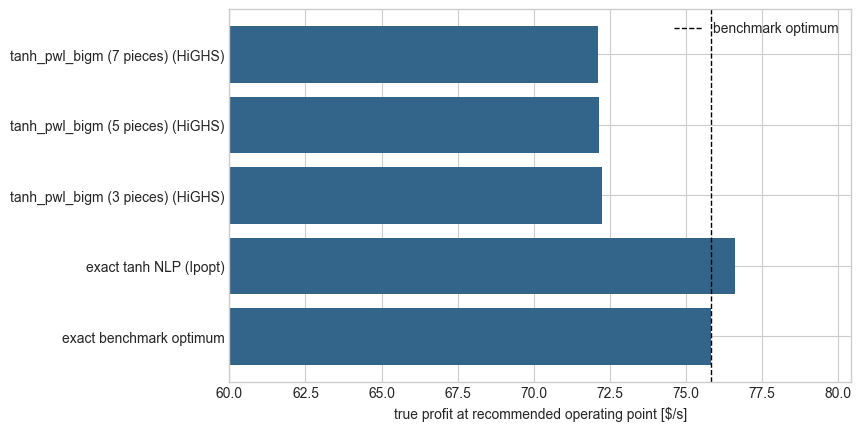

,case,FB*,TR*,"true profit at (FB*,TR*)",solve time [s]
0,exact benchmark optimum,4.389400,80.495000,75.820000,NaN
1,exact tanh NLP (Ipopt),4.386997,80.680164,76.597113,0.442168
2,tanh_pwl_bigm (3 pieces) (HiGHS),4.489895,80.374082,72.247425,0.411744
3,tanh_pwl_bigm (5 pieces) (HiGHS),4.489952,80.353852,72.157202,0.398319
4,tanh_pwl_bigm (7 pieces) (HiGHS),4.489992,80.339711,72.093967,0.398614


In [10]:
summary_rows = [{
    "case": "exact benchmark optimum",
    "FB*": EXACT_OPTIMUM["FB"],
    "TR*": EXACT_OPTIMUM["TR"],
    "true profit at (FB*,TR*)": EXACT_OPTIMUM["profit"],
}]
if exact_tanh_result is not None:
    summary_rows.append({
        "case": "exact tanh NLP (Ipopt)",
        "FB*": exact_tanh_result.fb,
        "TR*": exact_tanh_result.tr,
        "true profit at (FB*,TR*)": exact_tanh_result.exact_profit,
        "solve time [s]": exact_tanh_seconds,
    })
for row in milp_rows:
    if row["solver"] == "HiGHS":
        summary_rows.append({
            "case": f"{row['formulation']} (HiGHS)",
            "FB*": row["FB*"],
            "TR*": row["TR*"],
            "true profit at (FB*,TR*)": row["true profit at (FB*,TR*)"],
            "solve time [s]": row["solve time [s]"],
        })
summary = pd.DataFrame(summary_rows)

fig, ax = plt.subplots(figsize=(8.5, 4.2), constrained_layout=True)
labels = summary["case"]
ax.barh(labels, summary["true profit at (FB*,TR*)"], color="#33658a")
ax.axvline(EXACT_OPTIMUM["profit"], color="k", linestyle="--", linewidth=1.0, label="benchmark optimum")
ax.set_xlabel("true profit at recommended operating point [$/s]")
ax.set_xlim(left=min(60.0, float(summary["true profit at (FB*,TR*)"].min()) - 2.0))
ax.legend()
plt.show()

summary


### Operating-point visualisation

The constraint-aware operating-point map from notebooks 01 and 02, here for the PWL-tanh big-M MILP: the exact-profit landscape with the XA/XG feasibility boundaries, the MILP-selected operating point against the benchmark optimum, and the predicted-vs-exact composition at that point.

PWL(5) MILP optimum: FB=4.4900, TR=80.354, surrogate profit=61.184, true profit at that point=72.157


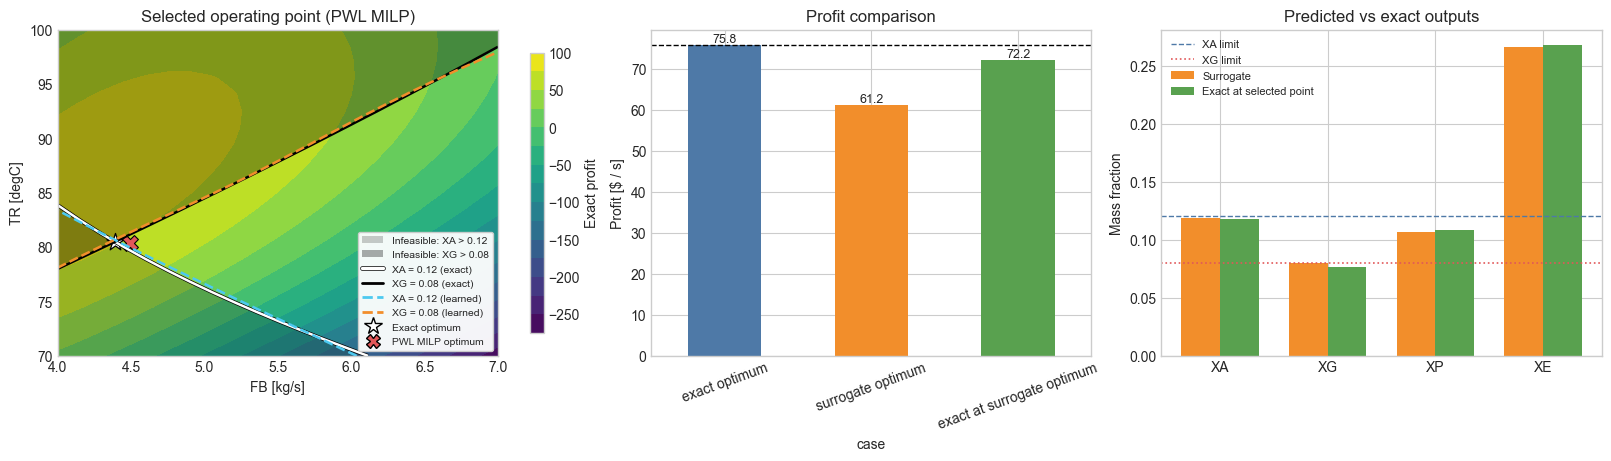

In [11]:
# Canonical PWL-tanh big-M MILP solve (5 pieces, HiGHS) for the
# operating-point visualisation, mirroring notebooks 01 and 02.
pwl_result = solve_surrogate_optimization_model(
    net.network,
    formulation="tanh_pwl_bigm",
    solver="appsi_highs",
    breakpoints=5,
    params=params,
)
print(f"PWL(5) MILP optimum: FB={pwl_result.fb:.4f}, TR={pwl_result.tr:.3f}, "
      f"surrogate profit={pwl_result.surrogate_profit:.3f}, "
      f"true profit at that point={pwl_result.exact_profit:.3f}")

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

fb_grid, tr_grid, exact_profit_grid = grid_values(plot_data, "profit")
_, _, xa_grid = grid_values(plot_data, "XA")
_, _, xg_grid = grid_values(plot_data, "XG")
# Learned constraint fields: what the (constraint-weighted) surrogate predicts.
_, _, xa_pred_grid = grid_values(plot_data, "XA_pred")
_, _, xg_pred_grid = grid_values(plot_data, "XG_pred")

contour = axes[0].contourf(fb_grid, tr_grid, exact_profit_grid, levels=16, cmap="viridis")
xa_upper = float(np.nanmax(xa_grid))
xg_upper = float(np.nanmax(xg_grid))
if xa_upper > params.xa_max:
    axes[0].contourf(fb_grid, tr_grid, xa_grid, levels=[params.xa_max, xa_upper], colors=["#171717"], alpha=0.22, antialiased=True)
if xg_upper > params.xg_max:
    axes[0].contourf(fb_grid, tr_grid, xg_grid, levels=[params.xg_max, xg_upper], colors=["#000000"], alpha=0.32, antialiased=True)
# Exact (true-process) feasibility boundaries.
xa_line = axes[0].contour(fb_grid, tr_grid, xa_grid, levels=[params.xa_max], colors="white", linewidths=1.8)
xg_line = axes[0].contour(fb_grid, tr_grid, xg_grid, levels=[params.xg_max], colors="black", linewidths=1.8)
xa_line.set_path_effects([pe.Stroke(linewidth=2.8, foreground="black"), pe.Normal()])
# Learned feasibility boundaries the MILP actually enforces (dashed).
xa_learned = axes[0].contour(fb_grid, tr_grid, xa_pred_grid, levels=[params.xa_max], colors="#4cc9f0", linewidths=1.8, linestyles="dashed")
xg_learned = axes[0].contour(fb_grid, tr_grid, xg_pred_grid, levels=[params.xg_max], colors="#f28e2b", linewidths=1.8, linestyles="dashed")
axes[0].scatter([pwl_result.exact_optimum["FB"]], [pwl_result.exact_optimum["TR"]], marker="*", s=170, color="white", edgecolor="black", linewidth=0.9)
axes[0].scatter([pwl_result.fb], [pwl_result.tr], marker="X", s=130, color="#e15759", edgecolor="black", linewidth=0.8)
axes[0].set_title("Selected operating point (PWL MILP)")
axes[0].set_xlabel("FB [kg/s]")
axes[0].set_ylabel("TR [degC]")
fig.colorbar(contour, ax=axes[0], shrink=0.86, label="Exact profit")

legend_handles = [
    Patch(facecolor="#171717", alpha=0.22, label="Infeasible: XA > 0.12"),
    Patch(facecolor="#000000", alpha=0.32, label="Infeasible: XG > 0.08"),
    Line2D([0], [0], color="white", lw=2.4, label="XA = 0.12 (exact)", path_effects=[pe.Stroke(linewidth=3.4, foreground="black"), pe.Normal()]),
    Line2D([0], [0], color="black", lw=2.0, label="XG = 0.08 (exact)"),
    Line2D([0], [0], color="#4cc9f0", lw=2.0, linestyle="dashed", label="XA = 0.12 (learned)"),
    Line2D([0], [0], color="#f28e2b", lw=2.0, linestyle="dashed", label="XG = 0.08 (learned)"),
    Line2D([0], [0], marker="*", color="white", markeredgecolor="black", markersize=13, linestyle="None", label="Exact optimum"),
    Line2D([0], [0], marker="X", color="#e15759", markeredgecolor="black", markersize=10, linestyle="None", label="PWL MILP optimum"),
]
axes[0].legend(handles=legend_handles, loc="lower right", frameon=True, framealpha=0.95, fontsize=7.5)

profit_rows = pd.DataFrame(pwl_result.comparison_rows())
profit_bars = profit_rows.set_index("case")["profit"]
colors = ["#4e79a7", "#f28e2b", "#59a14f"]
profit_bars.plot(kind="bar", ax=axes[1], color=colors, rot=20)
axes[1].set_title("Profit comparison")
axes[1].set_ylabel("Profit [$ / s]")
axes[1].axhline(pwl_result.exact_optimum["profit"], color="black", linestyle="--", linewidth=1.0)
for patch in axes[1].patches:
    height = patch.get_height()
    axes[1].annotate(f"{height:.1f}", (patch.get_x() + patch.get_width() / 2, height), ha="center", va="bottom", fontsize=9)

output_names = ["XA", "XG", "XP", "XE"]
x = np.arange(len(output_names))
width = 0.36
axes[2].bar(x - width / 2, [pwl_result.predicted_outputs[name] for name in output_names], width, label="Surrogate", color="#f28e2b")
axes[2].bar(x + width / 2, [pwl_result.exact_outputs[name] for name in output_names], width, label="Exact at selected point", color="#59a14f")
axes[2].axhline(params.xa_max, color="#4e79a7", linestyle="--", linewidth=1.0, label="XA limit")
axes[2].axhline(params.xg_max, color="#e15759", linestyle=":", linewidth=1.2, label="XG limit")
axes[2].set_xticks(x)
axes[2].set_xticklabels(output_names)
axes[2].set_title("Predicted vs exact outputs")
axes[2].set_ylabel("Mass fraction")
axes[2].legend(fontsize=8)

plt.show()

## Phase-2 objectives: MAE (MILP), MSE-QP (MIQP), MSE-SOCP (MISOCP)

An inverse-design demonstration: find the operating point whose **predicted**
composition best matches a target composition (here: the simulator state at the
benchmark optimum). With the big-M PWL block the problem class is set purely by
the loss formulation:

| loss | problem class | solver here |
|---|---|---|
| `mae` | MILP | HiGHS |
| `mse_qp` | MIQP | MOSEK |
| `mse_socp` | MISOCP | MOSEK |


In [12]:
target_state = solve_steady_state(EXACT_OPTIMUM["FB"], EXACT_OPTIMUM["TR"], params=params)
target = np.asarray(target_state.x, dtype=float)
print("target composition:", dict(zip(OUTPUT_NAMES, np.round(target, 4))))

inverse_rows = []
losses = [("mae", "HiGHS")]
if HAS_MOSEK:
    losses += [("mse_qp", "MOSEK"), ("mse_socp", "MOSEK")]

for loss_name, solver_label in losses:
    model, block = build_tanh_pwl_bigm_model(net.network, breakpoints=5, block_name="surrogate")
    attach_data_loss(
        model,
        [block.outputs[i] for i in range(len(OUTPUT_NAMES))],
        target,
        loss=loss_name,
    )
    solver = get_milp_solver() if solver_label == "HiGHS" else get_conic_solver()
    tic = time.perf_counter()
    solver.solve(model)
    seconds = time.perf_counter() - tic
    inverse_rows.append({
        "loss": loss_name,
        "problem class": {"mae": "MILP", "mse_qp": "MIQP", "mse_socp": "MISOCP"}[loss_name],
        "solver": solver_label,
        "FB*": float(pyo.value(block.inputs[0])),
        "TR*": float(pyo.value(block.inputs[1])),
        "mean loss": float(pyo.value(model.objective)),
        "solve time [s]": seconds,
    })

inverse = pd.DataFrame(inverse_rows)
print(f"target operating point: FB={EXACT_OPTIMUM['FB']}, TR={EXACT_OPTIMUM['TR']}")
inverse


target composition: {'XA': np.float64(0.12), 'XB': np.float64(0.3968), 'XC': np.float64(0.0239), 'XE': np.float64(0.2707), 'XG': np.float64(0.08), 'XP': np.float64(0.1087)}


target operating point: FB=4.3894, TR=80.495


,loss,problem class,solver,FB*,TR*,mean loss,solve time [s]
0,mae,MILP,HiGHS,4.391513,80.573287,0.001012,0.149928
1,mse_qp,MIQP,MOSEK,4.393021,80.424321,0.000003,0.093550
2,mse_socp,MISOCP,MOSEK,4.392234,80.414616,0.000003,0.085302


### Comparing the recommended result locations

The QP (MIQP) and SOCP (MISOCP) inverse-design solves minimise the **same**
squared-error objective through two different conic reformulations, so they
should recommend the **same operating point**; the MAE (MILP) solve minimises
the L1 error and lands close by. Below we put the recommended points side by
side in two pairings — **QP vs SOCP** and **QP vs MAE (MILP)** — each as a plot
and a table.

Each plot draws the pair of `(FB*, TR*)` points on the exact-profit landscape
together with the **learned feasibility boundaries** (`XA_pred = 0.12`,
`XG_pred = 0.08`, dashed) that the embedded optimizer actually enforces, with
the exact limits (solid) for reference; a zoom inset resolves the sub-`0.01`
separation between the points. The tables list each recommended `(FB*, TR*)`,
the surrogate's predicted constraint outputs there (samples of those same
learned boundaries), the per-objective mean loss, and the pairwise difference —
including the Euclidean distance between the two operating points.

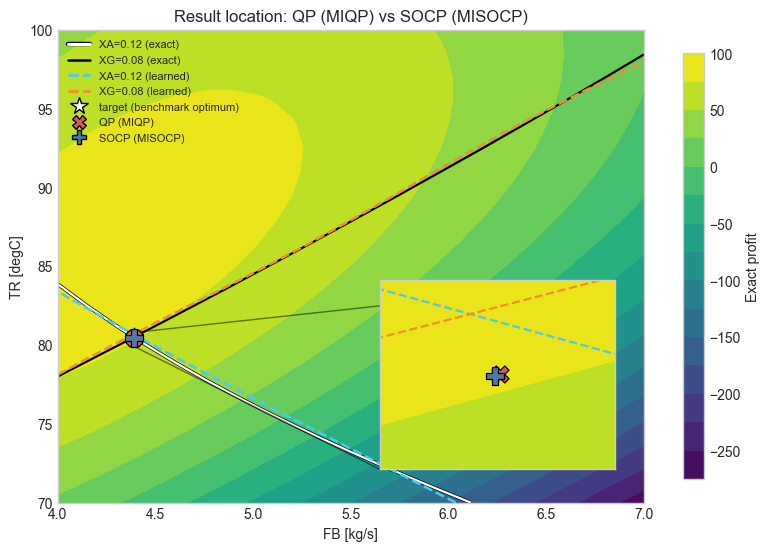

QP (MIQP) vs SOCP (MISOCP)


,FB*,TR*,XA_pred,XG_pred,mean loss,"dist(FB,TR)"
QP (MIQP),4.393021,80.424321,0.120658,0.078672,0.000003,NaN
SOCP (MISOCP),4.392234,80.414616,0.120705,0.078651,0.000003,NaN
|difference|,0.000787,0.009705,0.000046,0.000021,0.000000,0.009737


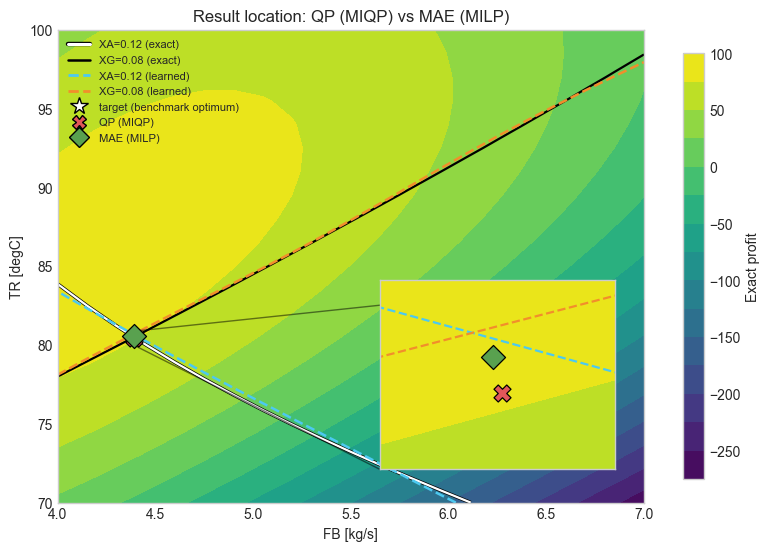

QP (MIQP) vs MAE (MILP)


,FB*,TR*,XA_pred,XG_pred,mean loss,"dist(FB,TR)"
QP (MIQP),4.393021,80.424321,0.120658,0.078672,0.000003,NaN
MAE (MILP),4.391513,80.573287,0.120233,0.079385,0.001012,NaN
|difference|,0.001508,0.148966,0.000425,0.000714,0.001010,0.148974


In [13]:
# Result-location comparison: QP vs SOCP, and QP vs MILP (MAE).
# QP (MIQP) and SOCP (MISOCP) minimise the SAME squared-error objective through
# two conic reformulations, so they should land on the same operating point; the
# MAE (MILP) solve minimises the L1 error and lands nearby. We overlay each pair
# of recommended points on the exact-profit landscape together with the LEARNED
# feasibility boundaries (XA_pred = 0.12, XG_pred = 0.08, dashed) -- the contours
# the embedded optimizer actually enforces -- and zoom in on the sub-0.01 split.
from IPython.display import display
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

if not HAS_MOSEK:
    print("QP/SOCP solves require MOSEK; skipping the result-location comparison.")
else:
    by_loss = {row["loss"]: dict(row) for row in inverse_rows}

    # Surrogate-predicted (learned) composition at each recommended point: the
    # learned constraint outputs XA_pred/XG_pred are samples of the same learned
    # boundary fields drawn below.
    for row in by_loss.values():
        pred = net.predict(np.array([[row["FB*"], row["TR*"]]], dtype=float))[0]
        for name, value in zip(OUTPUT_NAMES, pred):
            row[f"{name}_pred"] = float(value)

    STYLE = {
        "mse_qp": ("QP (MIQP)", "X", "#e15759"),
        "mse_socp": ("SOCP (MISOCP)", "P", "#4e79a7"),
        "mae": ("MAE (MILP)", "D", "#59a14f"),
    }

    def comparison_table(loss_a, loss_b):
        a, b = by_loss[loss_a], by_loss[loss_b]
        cols = ["FB*", "TR*", "XA_pred", "XG_pred", "mean loss"]
        table = pd.DataFrame(
            {
                STYLE[loss_a][0]: [a[c] for c in cols],
                STYLE[loss_b][0]: [b[c] for c in cols],
                "|difference|": [abs(a[c] - b[c]) for c in cols],
            },
            index=cols,
        ).T
        table["dist(FB,TR)"] = [np.nan, np.nan, float(np.hypot(a["FB*"] - b["FB*"], a["TR*"] - b["TR*"]))]
        return table

    fb_grid, tr_grid, profit_grid = grid_values(plot_data, "profit")
    _, _, xa_grid = grid_values(plot_data, "XA")
    _, _, xg_grid = grid_values(plot_data, "XG")
    _, _, xa_pred_grid = grid_values(plot_data, "XA_pred")
    _, _, xg_pred_grid = grid_values(plot_data, "XG_pred")

    def draw_pair(ax, loss_a, loss_b, title):
        contour = ax.contourf(fb_grid, tr_grid, profit_grid, levels=16, cmap="viridis")
        # Exact feasibility limits (solid, reference).
        xa_line = ax.contour(fb_grid, tr_grid, xa_grid, levels=[params.xa_max], colors="white", linewidths=1.6)
        xa_line.set_path_effects([pe.Stroke(linewidth=2.6, foreground="black"), pe.Normal()])
        ax.contour(fb_grid, tr_grid, xg_grid, levels=[params.xg_max], colors="black", linewidths=1.6)
        # Learned feasibility limits -- the bounds being compared (dashed).
        ax.contour(fb_grid, tr_grid, xa_pred_grid, levels=[params.xa_max], colors="#4cc9f0", linewidths=1.8, linestyles="dashed")
        ax.contour(fb_grid, tr_grid, xg_pred_grid, levels=[params.xg_max], colors="#f28e2b", linewidths=1.8, linestyles="dashed")
        ax.scatter([EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]], marker="*", s=180, color="white", edgecolor="black", linewidth=0.9, zorder=6)
        for loss in (loss_a, loss_b):
            _, marker, color = STYLE[loss]
            r = by_loss[loss]
            ax.scatter([r["FB*"]], [r["TR*"]], marker=marker, s=150, color=color, edgecolor="black", linewidth=0.9, zorder=7)
        ax.set_title(title)
        ax.set_xlabel("FB [kg/s]")
        ax.set_ylabel("TR [degC]")
        return contour

    def add_zoom(ax, loss_a, loss_b):
        a, b = by_loss[loss_a], by_loss[loss_b]
        cx, cy = 0.5 * (a["FB*"] + b["FB*"]), 0.5 * (a["TR*"] + b["TR*"])
        half_fb = max(abs(a["FB*"] - b["FB*"]) * 2.0, 0.02)
        half_tr = max(abs(a["TR*"] - b["TR*"]) * 2.0, 0.4)
        axins = ax.inset_axes([0.55, 0.07, 0.4, 0.4])
        axins.contourf(fb_grid, tr_grid, profit_grid, levels=16, cmap="viridis")
        axins.contour(fb_grid, tr_grid, xa_pred_grid, levels=[params.xa_max], colors="#4cc9f0", linewidths=1.6, linestyles="dashed")
        axins.contour(fb_grid, tr_grid, xg_pred_grid, levels=[params.xg_max], colors="#f28e2b", linewidths=1.6, linestyles="dashed")
        for loss in (loss_a, loss_b):
            _, marker, color = STYLE[loss]
            r = by_loss[loss]
            axins.scatter([r["FB*"]], [r["TR*"]], marker=marker, s=150, color=color, edgecolor="black", linewidth=0.9, zorder=7)
        axins.set_xlim(cx - half_fb, cx + half_fb)
        axins.set_ylim(cy - half_tr, cy + half_tr)
        axins.set_xticklabels([])
        axins.set_yticklabels([])
        ax.indicate_inset_zoom(axins, edgecolor="black")

    def pair_legend(loss_a, loss_b):
        handles = [
            Line2D([0], [0], color="white", lw=2.2, path_effects=[pe.Stroke(linewidth=3.2, foreground="black"), pe.Normal()], label="XA=0.12 (exact)"),
            Line2D([0], [0], color="black", lw=1.8, label="XG=0.08 (exact)"),
            Line2D([0], [0], color="#4cc9f0", lw=2.0, linestyle="dashed", label="XA=0.12 (learned)"),
            Line2D([0], [0], color="#f28e2b", lw=2.0, linestyle="dashed", label="XG=0.08 (learned)"),
            Line2D([0], [0], marker="*", color="white", markeredgecolor="black", markersize=13, linestyle="None", label="target (benchmark optimum)"),
        ]
        for loss in (loss_a, loss_b):
            label, marker, color = STYLE[loss]
            handles.append(Line2D([0], [0], marker=marker, color=color, markeredgecolor="black", markersize=10, linestyle="None", label=label))
        return handles

    for loss_a, loss_b, title in [
        ("mse_qp", "mse_socp", "Result location: QP (MIQP) vs SOCP (MISOCP)"),
        ("mse_qp", "mae", "Result location: QP (MIQP) vs MAE (MILP)"),
    ]:
        fig, ax = plt.subplots(figsize=(7.6, 5.4), constrained_layout=True)
        contour = draw_pair(ax, loss_a, loss_b, title)
        add_zoom(ax, loss_a, loss_b)
        fig.colorbar(contour, ax=ax, shrink=0.9, label="Exact profit")
        ax.legend(handles=pair_legend(loss_a, loss_b), loc="upper left", fontsize=8, framealpha=0.95)
        plt.show()
        print(f"{STYLE[loss_a][0]} vs {STYLE[loss_b][0]}")
        display(comparison_table(loss_a, loss_b).round(6))


## Conclusions

* The big-M PWL-tanh embedding turns the tanh surrogate optimization into a
  MILP that HiGHS and MOSEK solve in well under a second at this scale, while
  recommending operating points whose **true** profit is close to the
  exact-tanh NLP recommendation — and, unlike the local NLP solve, the MILP
  finds the surrogate's *global* optimum.
* Profit economics matter as much as the network formulation: a plain
  McCormick relaxation of `FB * XP` distorts the recommended operating point
  by tens of $/s, while the piecewise McCormick envelope (10 `FB` segments)
  shrinks the relaxation gap to a few percent.
* The remaining gap between surrogate-recommended and true-optimal profit is
  surrogate **model error** (profit is very sensitive to `XP`), not a
  formulation artifact — the case for more data and the Phase-4/5
  physics-informed losses.
* The MAE / MSE-QP / MSE-SOCP objective builders reproduce the architecture
  document's formulation matrix: the same PWL block becomes a MILP, MIQP, or
  MISOCP purely through the loss term, and the QP and SOCP variants agree at
  the optimum.
* The SOS2 variant of the same block awaits a SOS2-capable MILP solver
  (Gurobi/CPLEX/CBC/SCIP); the SOSX branching engine in Phase 6 will consume
  the same `PiecewiseLinearData`.


## Operating constraints: constrained vs unconstrained

All three embedding methods in this benchmark suite express the surrogate
outputs as decision variables of the Pyomo model, so the Williams-Otto
operating constraints `XA <= 0.12` and `XG <= 0.08` are **linear constraints
on those output variables**. They can therefore be added to every method:

| method | embedding | problem class with XA/XG limits |
|---|---|---|
| ReLU big-M | OMLT `relu_bigm` | MILP |
| exact tanh | OMLT `tanh_exact` | NLP |
| PWL-tanh big-M | `tanh_pwl_bigm` | MILP |

Below we solve the embedded problem **without** the operating constraints
(pure profit maximization) and **with** them, then compare the selected
operating points and the solver time.

In [14]:
import time

con = solve_surrogate_optimization_model(
    net.network, include_operating_constraints=True, params=params, formulation="tanh_pwl_bigm", solver="appsi_highs", breakpoints=5
)
unc = solve_surrogate_optimization_model(
    net.network, include_operating_constraints=False, params=params, formulation="tanh_pwl_bigm", solver="appsi_highs", breakpoints=5
)


def _constraint_row(case, r):
    return {
        "case": case,
        "FB": r.fb,
        "TR": r.tr,
        "surrogate profit": r.surrogate_profit,
        "true profit": r.exact_profit,
        "XA": r.predicted_outputs["XA"],
        "XG": r.predicted_outputs["XG"],
        "true feasible": r.exact_feasible,
        "solve time [s]": r.solve_seconds,
    }


constraint_table = pd.DataFrame(
    [
        _constraint_row("unconstrained", unc),
        _constraint_row("constrained (XA<=0.12, XG<=0.08)", con),
    ]
)
constraint_table

,case,FB,TR,surrogate profit,true profit,XA,XG,true feasible,solve time [s]
0,unconstrained,4.168560,91.205506,86.373693,81.603441,0.098318,0.133579,False,0.785704
1,"constrained (XA<=0.12, XG<=0.08)",4.489952,80.353852,61.183524,72.157202,0.118565,0.080000,True,0.391646


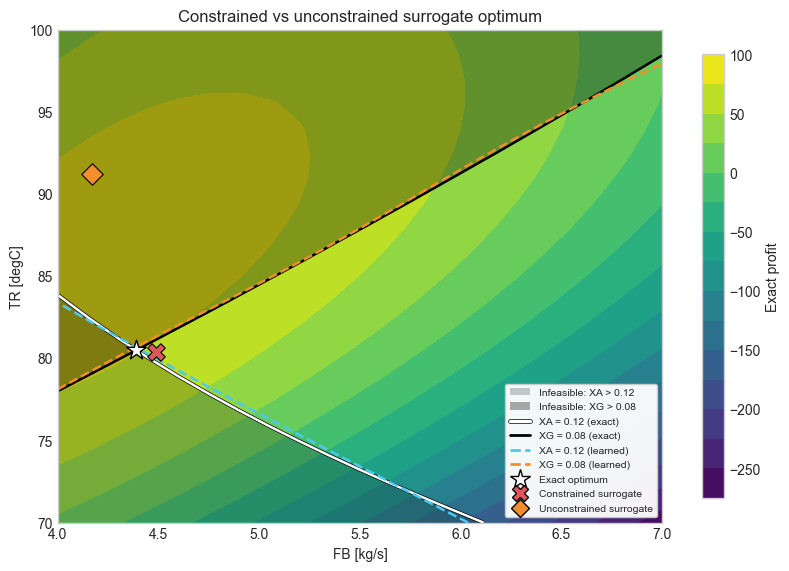

In [15]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

fig, ax = plt.subplots(figsize=(7.8, 5.6), constrained_layout=True)

fb_grid, tr_grid, profit_grid = grid_values(plot_data, "profit")
_, _, xa_grid = grid_values(plot_data, "XA")
_, _, xg_grid = grid_values(plot_data, "XG")
_, _, xa_pred_grid = grid_values(plot_data, "XA_pred")
_, _, xg_pred_grid = grid_values(plot_data, "XG_pred")

contour = ax.contourf(fb_grid, tr_grid, profit_grid, levels=16, cmap="viridis")
xa_upper = float(np.nanmax(xa_grid))
xg_upper = float(np.nanmax(xg_grid))
if xa_upper > params.xa_max:
    ax.contourf(fb_grid, tr_grid, xa_grid, levels=[params.xa_max, xa_upper], colors=["#171717"], alpha=0.22, antialiased=True)
if xg_upper > params.xg_max:
    ax.contourf(fb_grid, tr_grid, xg_grid, levels=[params.xg_max, xg_upper], colors=["#000000"], alpha=0.32, antialiased=True)
# Exact (solid) vs learned (dashed) feasibility boundaries. The constrained
# solve enforces the learned boundaries; the shading marks the true-infeasible
# region, so the gap between solid and dashed is the surrogate's constraint error.
xa_line = ax.contour(fb_grid, tr_grid, xa_grid, levels=[params.xa_max], colors="white", linewidths=1.8)
ax.contour(fb_grid, tr_grid, xg_grid, levels=[params.xg_max], colors="black", linewidths=1.8)
xa_line.set_path_effects([pe.Stroke(linewidth=2.8, foreground="black"), pe.Normal()])
ax.contour(fb_grid, tr_grid, xa_pred_grid, levels=[params.xa_max], colors="#4cc9f0", linewidths=1.8, linestyles="dashed")
ax.contour(fb_grid, tr_grid, xg_pred_grid, levels=[params.xg_max], colors="#f28e2b", linewidths=1.8, linestyles="dashed")

ax.scatter([con.exact_optimum["FB"]], [con.exact_optimum["TR"]], marker="*", s=220, color="white", edgecolor="black", linewidth=1.0, zorder=6)
ax.scatter([con.fb], [con.tr], marker="X", s=160, color="#e15759", edgecolor="black", linewidth=0.8, zorder=6)
ax.scatter([unc.fb], [unc.tr], marker="D", s=120, color="#f28e2b", edgecolor="black", linewidth=0.8, zorder=6)

ax.set_title("Constrained vs unconstrained surrogate optimum")
ax.set_xlabel("FB [kg/s]")
ax.set_ylabel("TR [degC]")
fig.colorbar(contour, ax=ax, shrink=0.9, label="Exact profit")

legend_handles = [
    Patch(facecolor="#171717", alpha=0.22, label="Infeasible: XA > 0.12"),
    Patch(facecolor="#000000", alpha=0.32, label="Infeasible: XG > 0.08"),
    Line2D([0], [0], color="white", lw=2.4, label="XA = 0.12 (exact)", path_effects=[pe.Stroke(linewidth=3.4, foreground="black"), pe.Normal()]),
    Line2D([0], [0], color="black", lw=2.0, label="XG = 0.08 (exact)"),
    Line2D([0], [0], color="#4cc9f0", lw=2.0, linestyle="dashed", label="XA = 0.12 (learned)"),
    Line2D([0], [0], color="#f28e2b", lw=2.0, linestyle="dashed", label="XG = 0.08 (learned)"),
    Line2D([0], [0], marker="*", color="white", markeredgecolor="black", markersize=15, linestyle="None", label="Exact optimum"),
    Line2D([0], [0], marker="X", color="#e15759", markeredgecolor="black", markersize=11, linestyle="None", label="Constrained surrogate"),
    Line2D([0], [0], marker="D", color="#f28e2b", markeredgecolor="black", markersize=9, linestyle="None", label="Unconstrained surrogate"),
]
ax.legend(handles=legend_handles, loc="lower right", frameon=True, framealpha=0.95, fontsize=7.5)

plt.show()